# Independent Executed PdM Companion — R15 Clean Execution

**Clean rerun of public v1.0.0 implementation; not exact historical Table 10 replication.**

All eight code cells were executed from scratch in the current Python environment. The original third-party dataset is not included in the distribution package.


## Setup
Install dependencies from `requirements.txt` and launch Jupyter from the repository root **or** `notebooks/`.
The following cell locates the repository automatically. Python 3.11 with the pinned dependencies is recommended, but the stored outputs were generated in a different environment.


In [1]:
from pathlib import Path
import os, sys, platform, json
candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent]
ROOT = next((p for p in candidates if (p / 'src' / 'run_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the repository root or notebooks/ directory')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Repository:', ROOT)
print('Python:', platform.python_version())


Repository: /mnt/data/PDM_R15_clean_execution/repository
Python: 3.13.5


## Dataset validation
Download the AI4I 2020 dataset independently and place it at `data/ai4i2020.csv`.
The CSV is **not included** in this package. A previously recovered local copy had SHA-256 `dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e` (not independently verified against the publisher).


In [2]:
import hashlib
import pandas as pd
from src.features import validate_dataset, engineer_features, ORIGINAL_FEATURES, FULL_FEATURES
DATA = ROOT / 'data' / 'ai4i2020.csv'
if not DATA.exists():
    raise FileNotFoundError(f'Missing {DATA}; download the public AI4I CSV first')
print('Input SHA-256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
raw = pd.read_csv(DATA)
validate_dataset(raw)
display(raw.head())


Input SHA-256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Engineering-grounded features (canonical source)
The six engineered variables below are produced by `src.features.engineer_features`; this cell is inspection-only.

In [3]:
engineered = engineer_features(raw)
display(engineered[["UDI"] + [c for c in FULL_FEATURES if c not in ORIGINAL_FEATURES]].head())
print("Original features:", ORIGINAL_FEATURES)
print("Physics-informed feature count:", len(FULL_FEATURES))


,UDI,Temperature Gradient,Approximate Spindle Power,Wear-Stress Index,Speed-Torque Ratio,TW Rolling Mean,TW Rolling Std
0,1,10.5,6.951079,0.0,36.238318,0.000000,0.000000
1,2,10.5,6.826220,138.9,30.410367,1.500000,2.121320
2,3,10.4,7.748817,247.0,30.323887,2.666667,2.516611
3,4,10.4,5.927068,276.5,36.278481,3.750000,2.986079
4,5,10.5,5.897382,360.0,35.200000,4.800000,3.492850


Original features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M', 'Type_H']
Physics-informed feature count: 14


## 4. Execute canonical experiment
Runs `python -m src.run_experiment` in the repository root and saves fresh outputs under `results/generated/`. **No published values are injected into generated outputs.**

In [4]:
import subprocess
command = [sys.executable, "-m", "src.run_experiment"]
result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
print(result.stdout[-12000:])
if result.returncode:
    print(result.stderr[-12000:])
    raise RuntimeError(f"Experiment exited with code {result.returncode}")
print("Canonical experiment completed.")


     feature_set   model  accuracy  precision  recall     f1  roc_auc  balanced_accuracy    mcc  latency_ms_per_sample   tn  fp  fn  tp
        Original      LR    0.8250     0.1421  0.8235 0.2424   0.9069             0.8243 0.2955                 0.0002 1594 338  12  56
        Original      IF    0.6990     0.0637  0.5735 0.1147   0.7261             0.6385 0.1089                 0.0184 1359 573  29  39
        Original      RF    0.9620     0.4636  0.7500 0.5730   0.9701             0.8597 0.5719                 0.0531 1873  59  17  51
        Original XGBoost    0.9730     0.5700  0.8382 0.6786   0.9731             0.9080 0.6785                 0.0040 1889  43  11  57
Physics-informed      LR    0.8715     0.1942  0.8824 0.3183   0.9392             0.8767 0.3778                 0.0002 1683 249   8  60
Physics-informed      IF    0.7345     0.0859  0.7059 0.1531   0.8050             0.7207 0.1783                 0.0180 1421 511  20  48
Physics-informed      RF    0.9745     0.5895  0

## 5. Fresh rerun metrics and predictions

In [5]:
GEN = ROOT / "results" / "generated"
metrics = pd.read_csv(GEN / "benchmark_and_ablation_metrics.csv")
preds = pd.read_csv(GEN / "test_predictions.csv")
display(metrics)
print("Prediction rows:", len(preds))
display(preds.head())


,feature_set,model,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,mcc,latency_ms_per_sample,tn,fp,fn,tp
0,Original,LR,0.8250,0.142132,0.823529,0.242424,0.906946,0.824291,0.295530,0.000167,1594,338,12,56
1,Original,IF,0.6990,0.063725,0.573529,0.114706,0.726114,0.638473,0.108914,0.018439,1359,573,29,39
2,Original,RF,0.9620,0.463636,0.750000,0.573034,0.970093,0.859731,0.571924,0.053056,1873,59,17,51
3,Original,XGBoost,0.9730,0.570000,0.838235,0.678571,0.973115,0.907989,0.678516,0.003975,1889,43,11,57
4,Physics-informed,LR,0.8715,0.194175,0.882353,0.318302,0.939182,0.876735,0.377810,0.000197,1683,249,8,60
5,Physics-informed,IF,0.7345,0.085868,0.705882,0.153110,0.804995,0.720695,0.178255,0.017970,1421,511,20,48
6,Physics-informed,RF,0.9745,0.589474,0.823529,0.687117,0.984133,0.901672,0.684463,0.057272,1893,39,12,56
7,Physics-informed,XGBoost,0.9755,0.600000,0.838235,0.699387,0.984640,0.909283,0.697433,0.004403,1894,38,11,57


Prediction rows: 16000


,row_index,UDI,feature_set,model,y_true,y_pred,y_score
0,2997,2998,Original,LR,0,1,0.971406
1,4871,4872,Original,LR,0,1,0.537994
2,3858,3859,Original,LR,0,1,0.680417
3,951,952,Original,LR,0,0,0.010430
4,6463,6464,Original,LR,0,1,0.854630


## 6. Visualize fresh rerun results

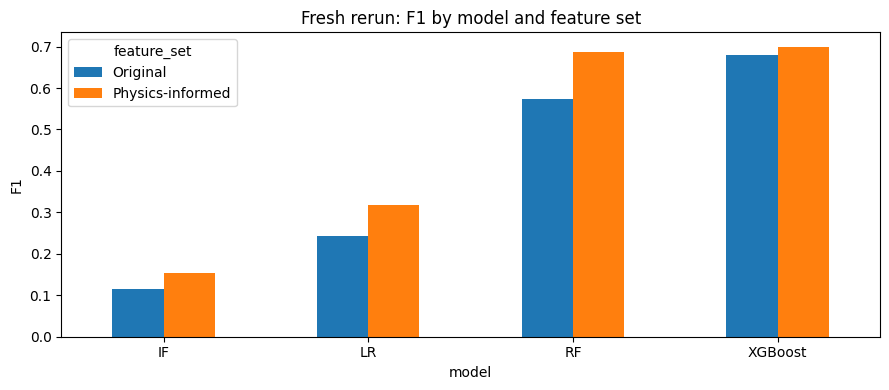

In [6]:
import matplotlib.pyplot as plt
pivot = metrics.pivot(index="model", columns="feature_set", values="f1")
ax = pivot.plot(kind="bar", figsize=(9, 4), rot=0, title="Fresh rerun: F1 by model and feature set")
ax.set_ylabel("F1")
plt.tight_layout()
plt.show()


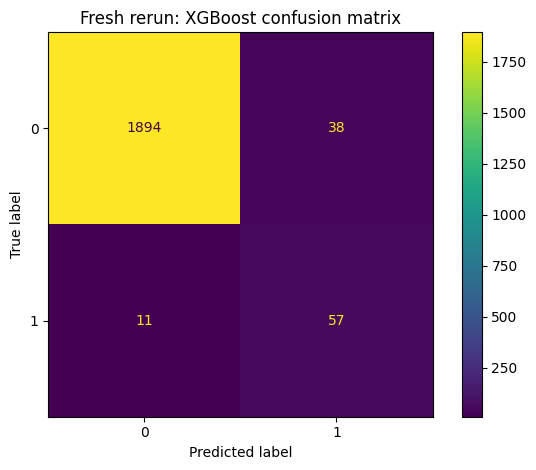

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
selected = preds[(preds["feature_set"] == "Physics-informed") & (preds["model"] == "XGBoost")]
assert not selected.empty
ConfusionMatrixDisplay.from_predictions(selected["y_true"], selected["y_pred"], values_format="d")
plt.title("Fresh rerun: XGBoost confusion matrix")
plt.tight_layout()
plt.show()


## 7. Published reference values vs fresh rerun
The CSV below is **transcribed published reference data**, not a freshly computed result. Exact agreement is not promised; see provenance and reproducibility documentation.

In [8]:
REF = ROOT / "results" / "published" / "table_10_benchmark_results.csv"
reference = pd.read_csv(REF)
display(reference.rename(columns=lambda x: "published_" + x if x != "model" else x))
comparison = metrics[metrics["feature_set"] == "Physics-informed"].merge(reference, on="model", suffixes=("_rerun", "_published"))
display(comparison)


,model,published_accuracy,published_precision,published_recall,published_f1,published_roc_auc,published_latency_ms
0,LR,0.865,0.198,0.897,0.324,0.940,0.61
1,IF,0.952,0.283,0.250,0.266,0.873,0.72
2,RF,0.986,0.633,0.838,0.722,0.983,2.51
3,XGBoost,0.978,0.439,0.853,0.580,0.972,0.35


,feature_set,model,accuracy_rerun,precision_rerun,recall_rerun,f1_rerun,roc_auc_rerun,balanced_accuracy,mcc,latency_ms_per_sample,tn,fp,fn,tp,accuracy_published,precision_published,recall_published,f1_published,roc_auc_published,latency_ms
0,Physics-informed,LR,0.8715,0.194175,0.882353,0.318302,0.939182,0.876735,0.377810,0.000197,1683,249,8,60,0.865,0.198,0.897,0.324,0.940,0.61
1,Physics-informed,IF,0.7345,0.085868,0.705882,0.153110,0.804995,0.720695,0.178255,0.017970,1421,511,20,48,0.952,0.283,0.250,0.266,0.873,0.72
2,Physics-informed,RF,0.9745,0.589474,0.823529,0.687117,0.984133,0.901672,0.684463,0.057272,1893,39,12,56,0.986,0.633,0.838,0.722,0.983,2.51
3,Physics-informed,XGBoost,0.9755,0.600000,0.838235,0.699387,0.984640,0.909283,0.697433,0.004403,1894,38,11,57,0.978,0.439,0.853,0.580,0.972,0.35


## Interpretation and limits
- These outputs document a **fresh independent execution** of the released source, not recovery of the original historical experiment.
- Published Table 10 is retained as a reference, not as ground truth for a new run.
- Different versions, feature encoding, class-imbalance handling and threshold protocols can change results.
- The article and released code contain feature-count and encoding description differences; see `RELEASE_NOTES_R14.md`.
- Do not tune against the held-out test set to force agreement with the article.
- The input dataset is a third-party public dataset and is not redistributed here.
